# Identifying Musical Style from Audio Features: A Case Study of Angine de Poitrine

**Course:** DT2470 Music Informatics

**Group Members:** Johanna Genander, Fanny Nyberg, Filip Svebeck

**Examiner:** Bobby Lee Townsend Sturm Jr.

## Research question
Can the unusual musical style of Angine de Poitrine (AdP) be identified from audio features alone, and which measurable characteristics, particularly rhythmic irregularity and microtonality, separate it from conventional rock?

## Hypotheses
- **H1 (rhythm):** AdP clips show higher inter-onset-interval variability and lower beat-tracking confidence / higher tempogram entropy than GTZAN rock.
- **H2 (pitch):** AdP clips deviate more from 12-tone equal temperament (12-TET); their fine-grained pitch-class histograms are flatter / have peaks off the semitone grid.
- **H3 (classification):** A linear classifier on rhythm and pitch features separates the two classes clearly above a majority-class baseline.

## Data
| Class | Source | Format | Target n |
|---|---|---|---|
| `adp` (positive) | 2 albums purchased on iTunes, sliced into 30 s segments | `.m4a` → `.wav` | ~100 |
| `rock` (negative) | GTZAN *rock* genre subset (Kaggle), already 30 s | `.wav` (22 050 Hz, mono) | 100 |

## Notebook Overview
Insert a table overview when the notebook is complete.

## 0. Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import librosa.display
import matplotlib.pyplot as plt

from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
SEED = 42
rng = np.random.default_rng(SEED)

# Audio settings
SR = 22050
SEG_SEC = 30
TARGET_DBFS = -20.0
MAX_SEG_PER_TRACK = 8

# General feature extraction
WIN_MS = 25
HOP_MS = 10

WIN = int(WIN_MS / 1000 * SR)
HOP = int(HOP_MS / 1000 * SR)

N_FFT = 2048
N_MFCC = 13

# Pitch analysis
PITCH_WIN = int(0.100 * SR)
PITCH_HOP = PITCH_WIN // 10

# Data paths
RAW_ADP = Path("raw-data/adp")
RAW_ROCK = Path("raw-data/rock")

WAV_ADP = Path("data/interim")
SEG_ADP = Path("data/processed")
CACHE = Path("cache")
FIGS = Path("figures")

for d in [WAV_ADP, SEG_ADP, CACHE, FIGS]:
    d.mkdir(parents=True, exist_ok=True)

## 1. Data Preparation

The dataset contains two classes:

- **Angine de Poitrine (AdP):** tracks from two purchased albums, converted to WAV and divided into 30-second segments.
- **Rock:** 100 pre-segmented 30-second excerpts from the GTZAN Rock dataset.

The goal is to construct a balanced dataset of approximately 200 clips. For the AdP material, the identity of the original track is retained so that segments from the same song can later be kept within the same cross-validation fold, preventing data leakage.

### 1.1 Convert AdP Audio to WAV

In [2]:
import subprocess

WAV_ADP.mkdir(parents=True, exist_ok=True)

adp_files = sorted(RAW_ADP.rglob("*.m4a"))

for src in adp_files:
    dst = WAV_ADP / f"{src.stem}.wav"

    if not dst.exists():
        subprocess.run(
            [
                "ffmpeg",
                "-y",
                "-i", str(src),
                "-ac", "1",
                "-ar", str(SR),
                str(dst)
            ],
            check=True,
            stdout=subprocess.DEVNULL,
            stderr=subprocess.DEVNULL
        )

All AdP recordings were converted to mono WAV at 22,050 Hz so that both datasets use the same audio format and sampling rate.

### 1.2 Split AdP Tracks Into 30-Second Segments
This is done because GTZAN consists of 30-second excerpts.

In [3]:
SEG_ADP.mkdir(parents=True, exist_ok=True)

segment_records = []

for wav_path in sorted(WAV_ADP.glob("*.wav")):
    y, sr = librosa.load(wav_path, sr=SR, mono=True)

    samples_per_segment = int(SEG_SEC * SR)
    n_segments = len(y) // samples_per_segment

    # Limit number of segments per original track
    n_keep = min(n_segments, MAX_SEG_PER_TRACK)

    if n_keep == 0:
        continue

    # Evenly spread selected segments across the track
    selected = np.linspace(
        0,
        n_segments - 1,
        n_keep,
        dtype=int
    )

    for seg_idx in selected:
        start = seg_idx * samples_per_segment
        end = start + samples_per_segment
        clip = y[start:end]

        out_path = SEG_ADP / f"{wav_path.stem}_seg{seg_idx:02d}.wav"
        sf.write(out_path, clip, SR)

        segment_records.append({
            "path": str(out_path),
            "label": 1,
            "label_name": "adp",
            "source_track": wav_path.stem,
            "segment_idx": seg_idx
        })

### 1.3 Index the GTZAN Rock Clips

In [4]:
rock_files = sorted(RAW_ROCK.rglob("*.wav"))[:100]

rock_records = []

for path in rock_files:
    rock_records.append({
        "path": str(path),
        "label": 0,
        "label_name": "rock",
        "source_track": path.stem,
        "segment_idx": 0
    })

### 1.4 Build the Dataset Manifest

In [5]:
manifest = pd.DataFrame(segment_records + rock_records)

manifest.insert(
    0,
    "clip_id",
    [f"clip_{i:03d}" for i in range(len(manifest))]
)

manifest.groupby("label_name").agg(
    n_clips=("clip_id", "count"),
    n_tracks=("source_track", "nunique")
)

,n_clips,n_tracks
label_name,,
adp,96,12
rock,100,100


The final dataset contains 196 audio excerpts: 96 Angine de Poitrine (AdP) segments derived from 12 original tracks and 100 GTZAN Rock excerpts. The classes are therefore approximately balanced. Since multiple AdP segments originate from the same track, the original track identity is retained for grouped cross-validation to prevent segments from the same recording appearing in both training and test sets.

## 2. Feature Extraction

Each feature extractor takes a waveform as input and returns a fixed-length set of scalar features. Features are grouped into three families:

- `rhy_`: rhythmic features
- `pit_`: pitch and tonal features
- `tim_`: timbral features

Many audio features are initially computed frame-by-frame over time. These are therefore summarized using statistics such as the mean, standard deviation, coefficient of variation, or entropy to obtain one fixed-length feature vector per 30-second clip.

The feature design is guided by the project hypotheses. Rhythmic features are used to investigate rhythmic irregularity, pitch-related features are used to investigate microtonality and tonal structure, and timbral features provide a conventional MIR baseline and help identify whether classification is driven by general recording or instrumentation differences rather than the hypothesized musical characteristics.

### 2.1 Shared Helper Functions

Several helper functions are used across the feature extraction pipeline. These include frame-based zero-crossing and spectral-centroid calculations, pitch-frequency conversion, peak selection in the time-frequency representation, audio loading and normalization, entropy calculation, and dynamic tempo estimation.

All clips are loaded as mono audio at 22,050 Hz and RMS-normalized before feature extraction to reduce loudness differences between the two datasets as a potential classification cue.


In [6]:
def zero_crossings_per_frame(x, frame_size, hop_size):
    """Return the number of sign changes in each complete frame of x."""
    x = np.asarray(x)
    crossings = []
    for start in range(0, len(x) - frame_size + 1, hop_size):
        frame = x[start:start + frame_size]
        signs = np.where(frame >= 0, 1, -1)
        crossings.append(np.count_nonzero(signs[:-1] != signs[1:]))
    return np.asarray(crossings, dtype=int)

def spectral_centroid_per_frame(x, frame_size, hop_size, sample_rate):
    """Return spectral centroids in Hz; silent frames receive a value of 0 Hz."""
    x = np.asarray(x, dtype=np.float64)
    frequencies = np.fft.rfftfreq(frame_size, d=1 / sample_rate)
    centroids = []
    for start in range(0, len(x) - frame_size + 1, hop_size):
        magnitude = np.abs(np.fft.rfft(x[start:start + frame_size]))
        denominator = magnitude.sum()
        centroids.append(np.dot(frequencies, magnitude) / denominator if denominator > 0 else 0.0)
    return np.asarray(centroids, dtype=np.float64)

# Equation 3.2 from Müller, 2015, Fundamentals of Music Processing
def f_pitch(p):
    """Convert MIDI pitch number to frequency in Hz."""
    return 440 * 2 ** ((p - 69) / 12)

def find_anchors(Sdb, sr, hop_length, dT=0.100, n_bands=25):
    """Loudest point in each dT x dF box, as (frame, bin) indices."""
    n_bins, n_frames = Sdb.shape
    dt_frames = int(round(dT * sr / hop_length))
    band_edges = np.linspace(0, n_bins, n_bands + 1).astype(int)

    t_idx, f_idx, db = [], [], []
    for t0 in range(0, n_frames, dt_frames):
        t1 = min(t0 + dt_frames, n_frames)
        for b in range(n_bands):
            f0, f1 = band_edges[b], band_edges[b + 1]
            box = Sdb[f0:f1, t0:t1]
            if box.size == 0:
                continue
            k, n = np.unravel_index(np.argmax(box), box.shape)
            t_idx.append(t0 + n)
            f_idx.append(f0 + k)
            db.append(box[k, n])
    return np.array(t_idx), np.array(f_idx), np.array(db)

def load_clip(path, target_dbfs=TARGET_DBFS):
    """Load a clip and RMS-normalise it, so loudness cannot act as a class cue."""
    y, _ = librosa.load(path, sr=SR, mono=True)
    y = librosa.util.fix_length(y, size=int(SEG_SEC * SR))
    rms = np.sqrt(np.mean(y ** 2)) + 1e-12
    y = y * (10 ** (target_dbfs / 20) / rms)
    peak = np.max(np.abs(y))
    return y / peak if peak > 1.0 else y # guard against clipping

def entropy(p):
    """Shannon entropy (bits) of a non-negative vector, normalised to sum 1."""
    p = np.clip(np.asarray(p, dtype=float), 0, None)
    total = p.sum()
    if total <= 0:
        return np.nan
    p = p[p > 0] / total
    return float(-(p * np.log2(p)).sum())


def dynamic_tempo(oenv):
    """Frame-wise tempo curve; the function moved between librosa versions."""
    try:
        return librosa.feature.rhythm.tempo(onset_envelope=oenv, sr=SR, hop_length=HOP, aggregate=None)
    except AttributeError:
        return librosa.beat.tempo(onset_envelope=oenv, sr=SR, hop_length=HOP, aggregate=None)

### 2.2 Rhythm Features

Rhythmic features are extracted to test whether Angine de Poitrine exhibits greater rhythmic irregularity than conventional rock.

Onsets are detected from the onset-strength envelope and used to calculate inter-onset intervals (IOIs). The primary feature for the rhythmic-irregularity hypothesis is the coefficient of variation of the IOIs (`rhy_ioi_cv`):

$$
CV_{\mathrm{IOI}} = \frac{\sigma_{\mathrm{IOI}}}{\mu_{\mathrm{IOI}}}
$$

Using the coefficient of variation rather than the standard deviation alone reduces the influence of overall tempo. Additional descriptors include tempo variability, onset rate, IOI entropy, pulse clarity, tempogram entropy, and deviation of detected onsets from the estimated beat grid.

In [7]:
def rhythm_features(y):
    oenv = librosa.onset.onset_strength(y=y, sr=SR, hop_length=HOP)
    f = {}

    tempo, beats = librosa.beat.beat_track(onset_envelope=oenv, sr=SR, hop_length=HOP, units="time")
    f["rhy_tempo"]      = float(np.atleast_1d(tempo)[0])
    f["rhy_beat_count"] = float(len(beats))
    f["rhy_tempo_std"]  = float(np.std(dynamic_tempo(oenv))) # tempo drift within the clip

    onsets = librosa.onset.onset_detect(onset_envelope=oenv, sr=SR, hop_length=HOP, units="time")
    ioi = np.diff(onsets)
    f["rhy_onset_rate"] = len(onsets) / SEG_SEC
    if len(ioi) >= 3:
        f["rhy_ioi_mean"]    = float(np.mean(ioi))
        f["rhy_ioi_std"]     = float(np.std(ioi))
        f["rhy_ioi_cv"]      = float(np.std(ioi) / (np.mean(ioi) + 1e-9))
        f["rhy_ioi_entropy"] = entropy(np.histogram(ioi, bins=20, range=(0, 2))[0])
    else:
        f.update(rhy_ioi_mean=np.nan, rhy_ioi_std=np.nan,
                 rhy_ioi_cv=np.nan, rhy_ioi_entropy=np.nan)

    ac = librosa.autocorrelate(oenv, max_size=len(oenv) // 2)
    ac = ac / (ac[0] + 1e-9)
    lag_min = int(round(0.25 * SR / HOP)) # ignore lags above 240 BPM
    f["rhy_pulse_clarity"] = float(ac[lag_min:].max()) if len(ac) > lag_min else np.nan

    tgram = librosa.feature.tempogram(onset_envelope=oenv, sr=SR, hop_length=HOP)
    f["rhy_tempogram_entropy"] = entropy(np.abs(tgram).mean(axis=1))

    if len(beats) > 2 and len(onsets) > 0:
        dev = np.abs(onsets[:, None] - beats[None, :]).min(axis=1)
        f["rhy_beat_sync_dev"] = float(np.mean(dev) / (np.median(np.diff(beats)) + 1e-9))
    else:
        f["rhy_beat_sync_dev"] = np.nan

    f["rhy_onset_env_mean"] = float(np.mean(oenv))
    f["rhy_onset_env_std"]  = float(np.std(oenv))
    return f

### 2.3 Pitch and Tonal Features

Pitch-related features are used to investigate harmonic structure and possible microtonality.

A log-frequency representation is first constructed by pooling spectral energy into MIDI pitch bands. These bands are then folded into 12 pitch classes to form a chromagram. Chroma statistics describe the distribution and stability of pitch classes across each clip.

In [8]:
_F_COEF = np.arange(PITCH_WIN // 2 + 1) * SR / PITCH_WIN
_PITCH_MASKS = [((_F_COEF >= f_pitch(p - 0.5)) & (_F_COEF < f_pitch(p + 0.5)))
                for p in range(128)]


def log_freq_spec(X):
    """Lab 03, part 2.2, eq 3.3-3.4: pool STFT power into MIDI pitch bands."""
    power = np.abs(X) ** 2
    return np.array([power[m].sum(axis=0) if m.any() else np.zeros(X.shape[1])
                     for m in _PITCH_MASKS])


def chromagram(Y):
    """Lab 03, part 2.3, eq 3.6."""
    chroma = np.zeros((12, Y.shape[1]))
    for p in range(128):
        chroma[p % 12] += Y[p]
    return chroma


def log_compress(v, gamma=100):
    """Lab 03, part 2.3, eq 3.8."""
    return np.log(1 + gamma * v)

#### Microtonality Measures

Microtonality is evaluated by measuring the deviation of estimated pitches from the nearest pitch in 12-tone equal temperament (12-TET).

Two complementary approaches are retained:

1. **Spectral grid concentration**, which measures how strongly prominent spectral peaks align to a common semitone grid.
2. **YIN-based pitch deviation**, which estimates the fundamental frequency and measures its mean distance from the nearest 12-TET semitone in cents.

The YIN-based measure (`pit_yin_dev_mean`) is treated as the primary feature for the microtonality hypothesis because spectral peak-based measures may also be affected by distortion, percussion, and spectral density.

In [9]:
# Pitch range for the f0 tracker: C2-C6 covers bass, guitar and vocal fundamentals.
F0_MIN = librosa.note_to_hz("C2")   # ~65 Hz
F0_MAX = librosa.note_to_hz("C6")   # ~1047 Hz
F0_HOP = 1024                       # coarser hop than elsewhere: pYIN is slow, and
                                    # pitch statistics do not need 10 ms resolution


def _parabolic_refine(col_db, k):
    """Sub-bin peak position by fitting a parabola through bins k-1, k, k+1."""
    if k <= 0 or k >= len(col_db) - 1:
        return 0.0
    a, b, c = col_db[k - 1], col_db[k], col_db[k + 1]
    denom = a - 2 * b + c
    return 0.0 if denom == 0 else float(np.clip(0.5 * (a - c) / denom, -0.5, 0.5))


def cents_from_semitone_grid(freqs_hz, tuning_semitones):
    """Distance in cents (0..50) from each frequency to the nearest 12-TET semitone."""
    cents = 1200 * np.log2(np.asarray(freqs_hz) / 440.0) - 100 * tuning_semitones
    return np.abs(((cents + 50) % 100) - 50)


def grid_concentration(freqs_hz):
    """Circular statistics on the 100-cent semitone circle.

    Returns (R, offset_cents, mean_abs_deviation). R is tuning-invariant by
    construction: 1 means every peak lands on one common semitone grid, 0 means
    the peaks are spread evenly and there is no grid to speak of.
    """
    cents = 1200 * np.log2(np.asarray(freqs_hz) / 440.0)
    ang = 2 * np.pi * ((cents % 100) / 100.0)
    C, S = np.cos(ang).mean(), np.sin(ang).mean()
    R = float(np.hypot(C, S))
    offset = float(np.arctan2(S, C) / (2 * np.pi) * 100)
    dev = float(np.abs(((cents - offset + 50) % 100) - 50).mean())
    return R, offset, dev


def f0_features(y):
    """Deviation of the fundamental frequency from 12-TET (primary H2 measure).

    Three steps, each fixing a weakness of plain YIN:
      1. Harmonic/percussive separation first, so drum hits are suppressed.
      2. pYIN decides WHICH frames are pitched (voiced_flag). Plain YIN returns
         a pitch for every frame, including drums and noise.
      3. YIN gives the f0 value in those frames. pYIN's own f0 is quantised to
         10-cent bins, too coarse to measure deviations of a few cents; YIN
         interpolates continuously. Frames where the two disagree by more than
         half a semitone (octave errors etc.) are dropped.
    The tuning offset is estimated from the voiced f0 values themselves, so a
    recording tuned slightly away from A440 is not mistaken for microtonality.
    """
    y_harm = librosa.effects.harmonic(y, margin=3.0)

    f0_pyin, voiced_flag, voiced_prob = librosa.pyin(
        y_harm, fmin=F0_MIN, fmax=F0_MAX, sr=SR,
        frame_length=N_FFT, hop_length=F0_HOP)
    f0_yin = librosa.yin(
        y_harm, fmin=F0_MIN, fmax=F0_MAX, sr=SR,
        frame_length=N_FFT, hop_length=F0_HOP)

    n = min(len(f0_yin), len(f0_pyin))
    f0_yin, f0_pyin = f0_yin[:n], f0_pyin[:n]
    voiced_flag, voiced_prob = voiced_flag[:n], voiced_prob[:n]

    with np.errstate(invalid="ignore", divide="ignore"):
        agree = np.abs(1200 * np.log2(f0_yin / f0_pyin)) < 50
    voiced = voiced_flag & (voiced_prob > 0.5) & np.isfinite(f0_pyin) & agree

    f = {"pit_voiced_fraction": float(voiced.mean())}
    if voiced.sum() < 20:
        f.update(pit_f0_tuning=np.nan, pit_yin_dev_mean=np.nan, pit_yin_dev_std=np.nan,
                 pit_f0_offgrid_frac=np.nan, pit_f0_median=np.nan, pit_f0_iqr=np.nan)
        return f

    f0 = f0_yin[voiced]
    tuning = float(librosa.pitch_tuning(f0))            # in semitones, -0.5..0.5
    dev = cents_from_semitone_grid(f0, tuning)          # 0 = on the grid, 50 = quarter-tone

    f["pit_f0_tuning"] = tuning
    f["pit_yin_dev_mean"] = float(np.mean(dev))
    f["pit_yin_dev_std"] = float(np.std(dev))
    f["pit_f0_offgrid_frac"] = float(np.mean(dev > 25))  # closer to a quarter-tone than to a semitone
    f["pit_f0_median"] = float(np.median(f0))
    f["pit_f0_iqr"] = float(np.subtract(*np.percentile(f0, [75, 25])))
    return f


def tonal_features(y):
    f = {}

    tuning = float(librosa.estimate_tuning(y=y, sr=SR))
    f["pit_tuning_offset"] = tuning

    X = librosa.stft(y, n_fft=PITCH_WIN, win_length=PITCH_WIN,
                     hop_length=PITCH_HOP, window="hann")
    Y = log_freq_spec(X)
    chroma = log_compress(chromagram(Y))
    chroma_mean = chroma.mean(axis=1)
    for i, v in enumerate(chroma_mean):
        f[f"pit_chroma_{i:02d}"] = float(v)
    f["pit_chroma_entropy"] = entropy(chroma_mean)  # high -> no tonal centre
    f["pit_chroma_std"] = float(chroma.std(axis=1).mean())

    Sdb = librosa.amplitude_to_db(np.abs(X), ref=np.max)
    t_idx, f_idx, db = find_anchors(Sdb, SR, PITCH_HOP)
    bin_hz = SR / PITCH_WIN
    keep = np.flatnonzero((db > -40) & (f_idx > 2) & (f_idx < Sdb.shape[0] - 3))
    peaks = np.array([(f_idx[i] + _parabolic_refine(Sdb[:, t_idx[i]], f_idx[i])) * bin_hz
                      for i in keep]) if len(keep) > 20 else np.array([])
    peaks = peaks[(peaks > 80) & (peaks < 1500)]  # where pitched content lives
    if len(peaks) > 20:
        R, offset_cents, dev = grid_concentration(peaks)
        f["pit_grid_concentration"] = R
        f["pit_peak_tuning_cents"] = offset_cents
        f["pit_peak_dev_mean"] = dev
    else:
        f.update(pit_grid_concentration=np.nan, pit_peak_tuning_cents=np.nan,
                 pit_peak_dev_mean=np.nan)

    f.update(f0_features(y))
    return f

In [10]:
# Quick check of the f0 measure on 6 clips before running the full extraction.
# Expect: voiced fraction varying between clips, and rock deviation well below
# the ~19 cents of the old measure (25 = no relation to the semitone grid).
import time

sample = pd.concat([
    manifest[manifest["label_name"] == "adp"].sample(3, random_state=SEED),
    manifest[manifest["label_name"] == "rock"].sample(3, random_state=SEED),
])

for r in sample.itertuples():
    t0 = time.time()
    f = f0_features(load_clip(r.path))
    print(f"{r.label_name:4s} {Path(r.path).stem[:30]:30s} "
          f"voiced={f['pit_voiced_fraction']:.2f}  "
          f"dev={f['pit_yin_dev_mean']:5.1f} cents  "
          f"offgrid={f['pit_f0_offgrid_frac']:.2f}  "
          f"({time.time() - t0:.1f} s)")

adp  06 Angor_seg00                 voiced=0.08  dev= 12.3 cents  offgrid=0.12  (3.9 s)
adp  05 Yor Zarad_seg07             voiced=0.07  dev=  7.6 cents  offgrid=0.04  (1.9 s)
adp  05 Yor Zarad_seg01             voiced=0.23  dev= 11.4 cents  offgrid=0.17  (1.9 s)
rock rock.00083                     voiced=0.00  dev=  nan cents  offgrid=nan  (1.9 s)
rock rock.00053                     voiced=0.00  dev=  nan cents  offgrid=nan  (1.9 s)
rock rock.00070                     voiced=0.04  dev=  8.6 cents  offgrid=0.08  (1.9 s)


### 2.4 Timbre Features

Timbral features are included to provide a conventional MIR representation of the recordings and to determine whether classification is driven primarily by rhythm and pitch or by broader differences in instrumentation, production, and spectral characteristics.

The extracted timbral descriptors include zero-crossing rate, spectral centroid, 13 MFCC coefficients, spectral bandwidth, rolloff, flatness, and RMS energy. Frame-level descriptors are summarized using their mean and standard deviation.

In [11]:
def timbre_features(y):
    f = {}

    zc = zero_crossings_per_frame(y, WIN, HOP)
    sc = spectral_centroid_per_frame(y, WIN + WIN % 2, HOP, SR)
    f["tim_zc_mean"], f["tim_zc_std"] = float(zc.mean()), float(zc.std())
    f["tim_sc_mean"], f["tim_sc_std"] = float(sc.mean()), float(sc.std())

    mfcc = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=N_MFCC, n_fft=N_FFT,
                                win_length=WIN, hop_length=HOP, window="hann")
    for i in range(N_MFCC):
        f[f"tim_mfcc{i:02d}_mean"] = float(mfcc[i].mean())
        f[f"tim_mfcc{i:02d}_std"]  = float(mfcc[i].std())

    for name, vals in [
        ("bandwidth", librosa.feature.spectral_bandwidth(y=y, sr=SR, hop_length=HOP)[0]),
        ("rolloff",   librosa.feature.spectral_rolloff(y=y, sr=SR, hop_length=HOP)[0]),
        ("flatness",  librosa.feature.spectral_flatness(y=y, hop_length=HOP)[0]),
        ("rms",       librosa.feature.rms(y=y, hop_length=HOP)[0]),
    ]:
        f[f"tim_{name}_mean"] = float(vals.mean())
        f[f"tim_{name}_std"]  = float(vals.std())
    return f

### 2.5 Extract Features for All Clips

The three feature families are extracted for every clip in the dataset and combined with the dataset manifest. The resulting table contains one row per 30-second clip and one column per extracted feature.

Feature extraction is cached to disk so that the complete audio analysis does not need to be repeated every time the notebook is executed.

In [12]:
def extract_all(path):
    y = load_clip(path)
    out = {}
    for fn in (rhythm_features, tonal_features, timbre_features):
        try:
            out.update(fn(y))
        except Exception as e:
            print(f"  ! {fn.__name__} failed on {Path(path).name}: {e}")
    return out


def build_features(manifest, cache=CACHE / "features.csv", force=False):
    if cache.exists() and not force:
        print(f"Loaded cached features from {cache}")
        return pd.read_csv(cache)

    rows = []
    for n, r in enumerate(manifest.itertuples(), 1):
        if n % 20 == 0 or n == 1:
            print(f"  {n}/{len(manifest)}")
        rows.append({"clip_id": r.clip_id, **extract_all(r.path)})

    feats = manifest.merge(pd.DataFrame(rows), on="clip_id")
    feats.to_csv(cache, index=False)
    print(f"Saved {feats.shape[0]} x {feats.shape[1]} to {cache}")
    return feats

features = build_features(manifest)

FEATURE_COLS = [
    c for c in features.columns
    if c.startswith(("rhy_", "pit_", "tim_"))
]

print(
    f"{len(FEATURE_COLS)} features: "
    f"{sum(c.startswith('rhy_') for c in FEATURE_COLS)} rhythm, "
    f"{sum(c.startswith('pit_') for c in FEATURE_COLS)} pitch/tonal, "
    f"{sum(c.startswith('tim_') for c in FEATURE_COLS)} timbre"
)

Loaded cached features from cache\features.csv
76 features: 13 rhythm, 25 pitch/tonal, 38 timbre


## 3. Analysis

This section examines how the extracted audio features differ between Angine de Poitrine and conventional rock before any classification model is trained.

The analysis focuses first on the two hypothesis-driven features:

- `rhy_ioi_cv`, representing rhythmic irregularity.
- `pit_yin_dev_mean`, representing mean pitch deviation from the nearest 12-TET semitone.

Additional features are then compared to determine which musical dimensions show the strongest differences between the two groups. This exploratory analysis also helps identify potential dataset or recording-related confounds before classification.

### 3.1 Class-Conditional Feature Distributions

The distributions of the two primary hypothesis features are compared between the AdP and rock classes.

For H1, a higher `rhy_ioi_cv` indicates greater variability in inter-onset intervals and therefore greater rhythmic irregularity.

For H2, a higher `pit_yin_dev_mean` indicates that estimated pitches lie further from the nearest 12-tone equal-tempered semitone.

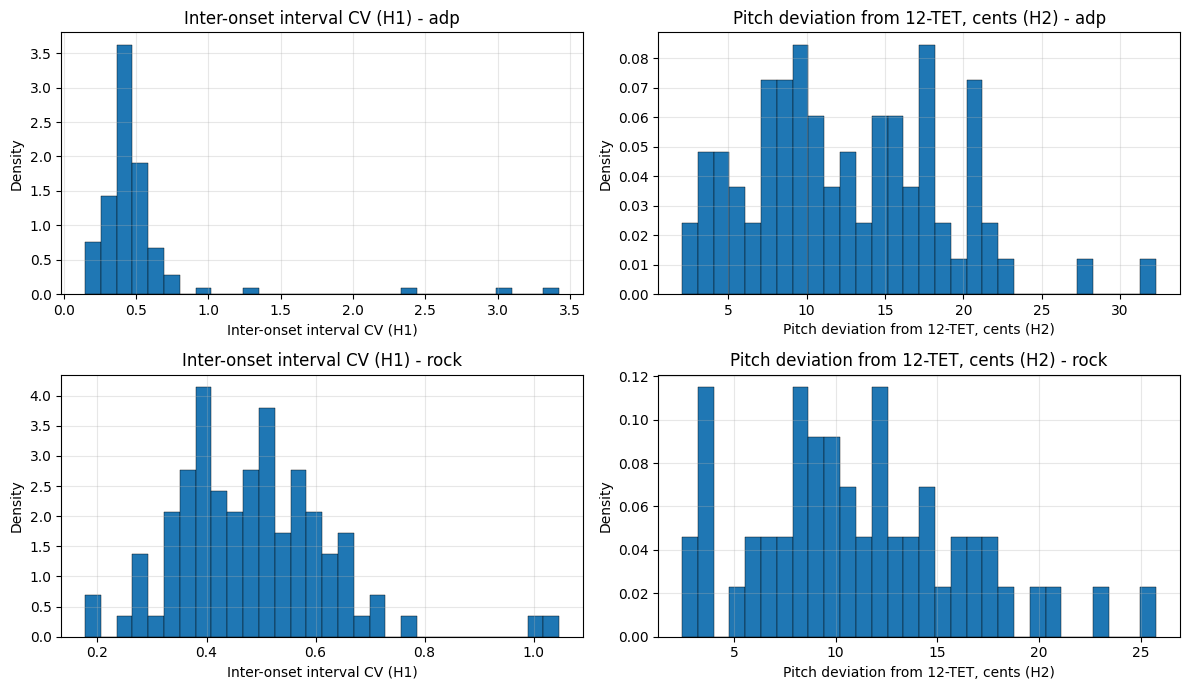

In [13]:
KEY_FEATURES = [
    "rhy_ioi_cv",
    "pit_yin_dev_mean"
]

KEY_LABELS = [
    "Inter-onset interval CV (H1)",
    "Pitch deviation from 12-TET, cents (H2)"
]

fig, axs = plt.subplots(2, len(KEY_FEATURES), figsize=(12, 7))

for col, (feat, label) in enumerate(zip(KEY_FEATURES, KEY_LABELS)):
    for row, cls in enumerate(["adp", "rock"]):
        values = features.loc[
            features["label_name"] == cls,
            feat
        ].dropna()

        ax = axs[row, col]

        ax.hist(
            values,
            bins=30,
            density=True,
            edgecolor="black",
            linewidth=0.3
        )

        ax.set_title(f"{label} - {cls}")
        ax.set_xlabel(label)
        ax.set_ylabel("Density")
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [14]:
for feat, label in zip(KEY_FEATURES, KEY_LABELS):
    for cls in ["adp", "rock"]:
        values = features.loc[
            features["label_name"] == cls,
            feat
        ].dropna()

        print(
            f"{cls:5s} {label:40s} "
            f"mean={values.mean():.3f} "
            f"std={values.std():.3f} "
            f"median={values.median():.3f}"
        )

adp   Inter-onset interval CV (H1)             mean=0.531 std=0.471 median=0.445
rock  Inter-onset interval CV (H1)             mean=0.485 std=0.141 median=0.481
adp   Pitch deviation from 12-TET, cents (H2)  mean=12.576 std=6.125 median=11.763
rock  Pitch deviation from 12-TET, cents (H2)  mean=11.102 std=5.182 median=10.359


In [15]:
def cliffs_delta(a, b):
    """Non-parametric effect size in [-1, 1]: P(a > b) - P(a < b).

    Rough guide (Romano et al., 2006): |d| < 0.147 negligible, < 0.33 small,
    < 0.474 medium, otherwise large.
    """
    a, b = np.asarray(a), np.asarray(b)
    greater = (a[:, None] > b[None, :]).sum()
    less = (a[:, None] < b[None, :]).sum()
    return (greater - less) / (len(a) * len(b))


def compare_classes(df, feature, level="clip"):
    """Mann-Whitney U test and Cliff's delta for one feature, AdP vs rock.

    level="clip":  every 30 s segment counts as one observation (96 vs 100).
    level="track": AdP segments are first reduced to one median per original
                   track (12 vs 100), since segments from the same track are
                   not independent observations.
    """
    adp = df[df["label_name"] == "adp"]
    rock = df[df["label_name"] == "rock"]

    if level == "track":
        a = adp.groupby("source_track")[feature].median().dropna().values
    else:
        a = adp[feature].dropna().values
    b = rock[feature].dropna().values

    _, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    return {
        "feature": feature,
        "level": level,
        "n_adp": len(a),
        "n_rock": len(b),
        "median_adp": np.median(a),
        "median_rock": np.median(b),
        "cliffs_delta": cliffs_delta(a, b),
        "p_value": p,
    }


hypothesis_tests = pd.DataFrame([
    compare_classes(features, feat, level)
    for feat in KEY_FEATURES
    for level in ["clip", "track"]
])

hypothesis_tests.round(3)

,feature,level,n_adp,n_rock,median_adp,median_rock,cliffs_delta,p_value
0,rhy_ioi_cv,clip,96,100,0.445,0.481,-0.124,0.134
1,rhy_ioi_cv,track,12,100,0.418,0.481,-0.250,0.160
2,pit_yin_dev_mean,clip,82,56,11.763,10.359,0.138,0.171
3,pit_yin_dev_mean,track,11,56,11.750,10.359,0.130,0.504


#### Interpretation

Neither hypothesis feature differs between the classes. Cliff's delta is small or negligible and no p-value falls below 0.05, at either clip or track level (table above). The track-level test is the more trustworthy of the two: segments from the same AdP track share tempo, key and production, so the 96 segments represent only 12 independent sources.

**H1 (rhythmic irregularity) is not supported by this measure.** The median IOI coefficient of variation is in fact slightly *lower* for AdP (0.445) than for rock (0.481). The higher AdP mean comes from a handful of segments with values well beyond the rock maximum (≈1.05). These are mostly opening or closing segments of a track, or segments containing a pause, where a single long gap between onsets inflates the standard deviation. The IOI coefficient of variation measures timing variability at the level of individual events. Irregularity that lies in how beats are *grouped* (for example odd meters or a shortened bar) leaves the inter-onset intervals regular and is therefore invisible to this feature.

**H2 (microtonality) receives at most weak support.** After restricting the measure to frames where pYIN detects a clear fundamental, the deviation sits well below the 25 cents expected for frequencies unrelated to the semitone grid (rock median 10.4 cents), so the measure now captures real pitch structure. AdP deviates slightly more (median 11.8 cents), in the direction predicted by H2, but the effect is small (Cliff's δ ≈ 0.13) and not significant at either clip or track level. The measure can only be computed where a single dominant pitch is present: 82 of 96 AdP segments (11 of 12 tracks) but only 56 of 100 rock clips. Dense, distorted rock mixes rarely contain one clear fundamental, so the rock sample is biased toward its sparser, more clearly pitched excerpts, and the comparison should be read with that limitation in mind.

## 4. Classification

This section tests **H3**: whether a classifier trained on rhythm and pitch features separates AdP from rock clearly above a majority-class baseline. It then asks which feature family the separation actually comes from.

**Evaluation design.**
- *Grouped cross-validation.* Segments from the same AdP track share tempo, key, instrumentation and production. If segments of one track appeared in both training and test data, a model could recognise the track rather than the style. `StratifiedGroupKFold` with `source_track` as the group keeps every track entirely within one fold, while keeping the class balance in each fold. With 12 AdP tracks and 5 folds, each test fold contains 2–3 AdP tracks.
- *Preprocessing inside the pipeline.* Imputation and standardisation are fitted on the training folds only.
- *No hyperparameter tuning.* Both models use library defaults (C = 1). With only 12 independent AdP sources, tuning would require nested cross-validation and would risk fitting the noise of individual folds.
- *f0-based features are excluded.* They are missing for 44 % of rock clips but only 15 % of AdP clips, so the imputed value would itself reveal the class.

AdP is the positive class, so precision and recall refer to AdP.

### 4.1 Setup

In [16]:
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import make_scorer
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline

# f0-based features exist only where pYIN finds a clear fundamental. They are missing
# for 44 % of rock clips but only 15 % of AdP clips, so any imputed value would itself
# reveal the class. They are used in the analysis (Section 3) but excluded here.
F0_COLS = ["pit_yin_dev_mean", "pit_yin_dev_std", "pit_f0_offgrid_frac",
           "pit_f0_tuning", "pit_f0_median", "pit_f0_iqr"]
MODEL_COLS = [c for c in FEATURE_COLS if c not in F0_COLS]

FEATURE_SETS = {
    "rhythm": [c for c in MODEL_COLS if c.startswith("rhy_")],
    "pitch":  [c for c in MODEL_COLS if c.startswith("pit_")],
    "timbre": [c for c in MODEL_COLS if c.startswith("tim_")],
}
FEATURE_SETS["rhythm + pitch"] = FEATURE_SETS["rhythm"] + FEATURE_SETS["pitch"]  # the H3 feature set
FEATURE_SETS["all"] = MODEL_COLS

y = features["label"].values               # 1 = AdP (positive class), 0 = rock
groups = features["source_track"].values   # keeps all segments of a track in the same fold

# Stratified + grouped: every fold holds out whole tracks AND keeps the class balance.
# With only 12 AdP tracks, each test fold contains 2-3 of them.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)


def make_models():
    """Fresh, unfitted models. Imputation and scaling sit inside the pipeline so they
    are re-fitted on the training folds only and never see the test fold."""
    return {
        "Majority baseline": DummyClassifier(strategy="most_frequent"),
        "Logistic regression": make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            LogisticRegression(max_iter=5000)),
        "SVM (RBF)": make_pipeline(
            SimpleImputer(strategy="median"), StandardScaler(),
            SVC(kernel="rbf", C=1.0, gamma="scale")),
    }


SCORING = {
    "accuracy":  "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall":    make_scorer(recall_score, zero_division=0),
    "f1":        make_scorer(f1_score, zero_division=0),
}


def evaluate(model, cols):
    """Grouped 5-fold CV. Returns mean and std over folds for each metric."""
    res = cross_validate(model, features[cols], y, groups=groups, cv=cv, scoring=SCORING)
    out = {}
    for m in SCORING:
        out[m] = res[f"test_{m}"].mean()
        out[f"{m}_std"] = res[f"test_{m}"].std()
    return out


for name, cols in FEATURE_SETS.items():
    print(f"{name:15s} {len(cols):3d} features")

rhythm           13 features
pitch            19 features
timbre           38 features
rhythm + pitch   32 features
all              70 features


### 4.2 H3: Rhythm and Pitch Features

In [17]:
# H3: can a classifier on rhythm and pitch features separate the classes
# clearly above the majority baseline?
h3_cols = FEATURE_SETS["rhythm + pitch"]

rows = []
for name, model in make_models().items():
    r = evaluate(model, h3_cols)
    rows.append({"model": name,
                 **{m: f"{r[m]:.2f} ± {r[m + '_std']:.2f}" for m in SCORING}})

h3_results = pd.DataFrame(rows).set_index("model")
h3_results

,accuracy,precision,recall,f1
model,,,,
Majority baseline,0.52 ± 0.05,0.00 ± 0.00,0.00 ± 0.00,0.00 ± 0.00
Logistic regression,0.87 ± 0.02,0.86 ± 0.03,0.89 ± 0.06,0.87 ± 0.02
SVM (RBF),0.90 ± 0.03,0.88 ± 0.04,0.93 ± 0.04,0.90 ± 0.03


### 4.3 Confusion Matrix and Misclassified Clips

The confusion matrix pools the predictions of all five test folds, so every clip is predicted exactly once by a model that never saw its track during training. The list of misclassified clips is the starting point for error analysis: listening to them shows what the model gets wrong.

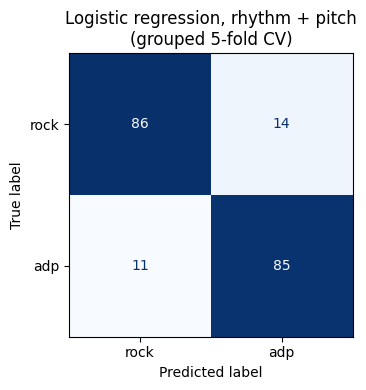

25 misclassified clips


,label_name,source_track,segment_idx
15,adp,01 Sherpa,10
31,adp,02 Tohogd,7
48,adp,04 Ababa hôtel,0
51,adp,04 Ababa hôtel,4
56,adp,04 Utzp,0
57,adp,04 Utzp,1
59,adp,04 Utzp,5
60,adp,04 Utzp,6
62,adp,04 Utzp,10
64,adp,05 Sahardnieh,0


In [18]:
# Confusion matrix pooled over the five test folds: every clip is predicted once,
# by a model that never saw its track during training.
h3_model = make_models()["Logistic regression"]
y_pred = cross_val_predict(h3_model, features[h3_cols], y, groups=groups, cv=cv)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y, y_pred),
                       display_labels=["rock", "adp"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Logistic regression, rhythm + pitch\n(grouped 5-fold CV)")
plt.tight_layout()
plt.savefig(FIGS / "confusion_h3.pdf", bbox_inches="tight")
plt.show()

# Which clips are misclassified? Listening to these is the quickest error analysis.
errors = features.loc[y_pred != y, ["label_name", "source_track", "segment_idx"]]
print(f"{len(errors)} misclassified clips")
errors.sort_values(["label_name", "source_track"])

### 4.4 Ablation by Feature Family

The same models are trained on one feature family at a time. This answers the second part of the research question: which kind of measurable characteristic separates AdP from rock. If timbre alone performs as well as all features together, the classifier relies mainly on sound and production rather than on the rhythmic and tonal properties the hypotheses are about.

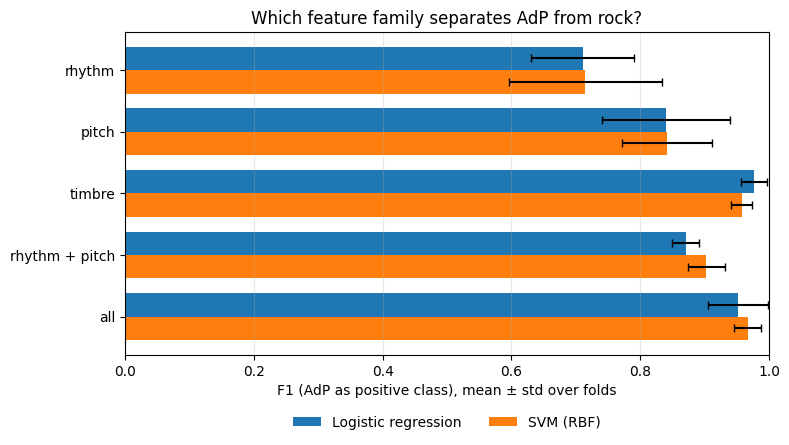

,features,model,n_features,accuracy,f1,f1_std
0,rhythm,Logistic regression,13,0.733,0.711,0.080
1,rhythm,SVM (RBF),13,0.742,0.715,0.119
2,pitch,Logistic regression,19,0.856,0.840,0.099
3,pitch,SVM (RBF),19,0.848,0.841,0.070
4,timbre,Logistic regression,38,0.976,0.977,0.020
5,timbre,SVM (RBF),38,0.959,0.958,0.016
6,rhythm + pitch,Logistic regression,32,0.873,0.870,0.022
7,rhythm + pitch,SVM (RBF),32,0.904,0.903,0.029
8,all,Logistic regression,70,0.953,0.952,0.046
9,all,SVM (RBF),70,0.969,0.967,0.020


In [19]:
# Ablation: the same models trained on one feature family at a time.
# This answers the second half of the research question - which kind of
# measurable characteristic actually separates AdP from rock.
rows = []
for set_name, cols in FEATURE_SETS.items():
    for model_name, model in make_models().items():
        if model_name == "Majority baseline":
            continue
        r = evaluate(model, cols)
        rows.append({"features": set_name, "model": model_name,
                     "n_features": len(cols), "accuracy": r["accuracy"],
                     "f1": r["f1"], "f1_std": r["f1_std"]})

ablation = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.6))
order = list(FEATURE_SETS)
width = 0.38
for i, (model_name, sub) in enumerate(ablation.groupby("model", sort=False)):
    sub = sub.set_index("features").loc[order]
    ax.barh(np.arange(len(order)) + (i - 0.5) * width, sub["f1"], xerr=sub["f1_std"],
            height=width, label=model_name, capsize=3)
ax.set_yticks(np.arange(len(order)), order)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("F1 (AdP as positive class), mean ± std over folds")
ax.set_title("Which feature family separates AdP from rock?")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGS / "ablation.pdf", bbox_inches="tight")
plt.show()

ablation.round(3)

#### Interpretation

**H3 is supported.** A classifier on rhythm and pitch features separates the classes far above the majority baseline: F1 = 0.87 ± 0.02 for logistic regression and 0.90 ± 0.03 for the SVM, against an accuracy of 0.52 for the baseline. Because whole tracks are held out in every fold, the models cannot have succeeded by recognising individual recordings.

**The separation comes mainly from timbre.** In the ablation, rhythm features alone are the weakest family (F1 ≈ 0.71), pitch features reach 0.84, and timbre features alone reach 0.96–0.98. Adding rhythm and pitch to timbre does not improve the result (0.95–0.97 with all features). Rhythm and pitch therefore carry real but secondary information; most of what distinguishes AdP from rock lies in the overall sound of the recordings. The pitch family here consists mainly of chroma statistics, and the measures aimed specifically at microtonality showed no significant difference in Section 3, so the pitch result most likely reflects tonal structure rather than tuning.

**Errors are concentrated.** Of the 25 misclassified clips, 11 are AdP and 14 rock. Five of the eight segments of *Utzp* are misclassified, which suggests that this track is closer to conventional rock than the rest of the material. Three further AdP errors are opening segments (*Ababa hôtel*, *Utzp*, *Sahardnieh*), where an introduction differs from the body of the track. The rock errors are spread over 14 different clips.

## 5. Confound Check: Recording Bandwidth

The GTZAN excerpts were derived from lossy, band-limited sources: the mean rock spectrum falls steeply above about 9 kHz, while the AdP recordings extend to 11 kHz. Timbre features describe the shape of the spectrum, so a classifier could in principle separate the classes by this recording artefact rather than by anything musical.

Two checks address this:
1. **The band above 9 kHz on its own.** If this single value separates the classes, the artefact is real and available to any model.
2. **Timbre features on low-passed audio.** Both classes are filtered at 8 kHz, removing the band entirely, and the timbre features are recomputed. If performance stays close to the full-band result, the timbre separation does not depend on the codec cutoff.

In [20]:
from scipy.signal import butter, sosfiltfilt

# GTZAN clips come from lossy, band-limited sources: the mean rock spectrum falls
# steeply above ~8.5 kHz, while the AdP masters extend to 11 kHz. Low-passing BOTH
# classes at the same frequency removes that band, so whatever separation survives
# cannot come from the codec cutoff.
LOWPASS_HZ = 8000      # filter cutoff, safely below the GTZAN roll-off
HF_DIAG_HZ = 9000      # band where the GTZAN roll-off actually shows (diagnostic only)
_SOS = butter(8, LOWPASS_HZ, btype="low", fs=SR, output="sos")


def lowpass(y):
    """Zero-phase 8th-order Butterworth low-pass at LOWPASS_HZ."""
    return sosfiltfilt(_SOS, y)


def hf_energy_db(y, f_lo=HF_DIAG_HZ):
    """Share of total energy above f_lo, in dB. A direct measure of the codec cutoff."""
    S = np.abs(librosa.stft(y, n_fft=N_FFT, hop_length=HOP)) ** 2
    freqs = librosa.fft_frequencies(sr=SR, n_fft=N_FFT)
    return float(10 * np.log10(S[freqs >= f_lo].sum() / (S.sum() + 1e-12) + 1e-12))


def build_lowpass_timbre(manifest, cache=CACHE / "timbre_lowpass.csv", force=False):
    """Timbre features recomputed on low-passed audio, plus the high-frequency energy
    of the original audio. Cached separately; no pYIN, so it runs in a few minutes."""
    if cache.exists() and not force:
        print(f"Loaded cached low-pass features from {cache}")
        return pd.read_csv(cache)

    rows = []
    for n, r in enumerate(manifest.itertuples(), 1):
        if n % 20 == 0 or n == 1:
            print(f"  {n}/{len(manifest)}")
        y = load_clip(r.path)
        f_lp = timbre_features(lowpass(y))
        rows.append({"clip_id": r.clip_id,
                     "conf_hf_energy_db": hf_energy_db(y),
                     **{f"{k}_lp": v for k, v in f_lp.items()}})

    lp = pd.DataFrame(rows)
    lp.to_csv(cache, index=False)
    print(f"Saved {lp.shape[0]} x {lp.shape[1]} to {cache}")
    return lp


lp = build_lowpass_timbre(manifest).set_index("clip_id").loc[features["clip_id"]]
features[lp.columns] = lp.values   # same row order as `features`, safe to re-run

TIMBRE_LP_COLS = [c + "_lp" for c in FEATURE_SETS["timbre"]]
print(f"{len(TIMBRE_LP_COLS)} low-passed timbre features added")

  1/196
  20/196
  40/196
  60/196
  80/196
  100/196
  120/196
  140/196
  160/196
  180/196
Saved 196 x 40 to cache\timbre_lowpass.csv
38 low-passed timbre features added


C:\Users\filip_h9q5r71\AppData\Local\Temp\ipykernel_26300\242475100.py:48: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  features[lp.columns] = lp.values   # same row order as `features`, safe to re-run


In [21]:
# Three questions:
#  1. How much does the band above 9 kHz alone reveal the class?
#  2. Does timbre still separate the classes once that band is removed?
#  3. Does the full-band result change when the same features are low-passed?
confound_sets = {
    "energy above 9 kHz only":         ["conf_hf_energy_db"],
    "timbre, full band":               FEATURE_SETS["timbre"],
    f"timbre, low-passed at {LOWPASS_HZ // 1000} kHz": TIMBRE_LP_COLS,
}

rows = []
for set_name, cols in confound_sets.items():
    for model_name, model in make_models().items():
        if model_name == "Majority baseline":
            continue
        r = evaluate(model, cols)
        rows.append({"features": set_name, "model": model_name,
                     "accuracy": r["accuracy"], "f1": r["f1"], "f1_std": r["f1_std"]})

confound_results = pd.DataFrame(rows)

print("Energy above 9 kHz, median per class (dB relative to total):")
print(features.groupby("label_name")["conf_hf_energy_db"].median().round(1).to_string())

confound_results.round(3)

Energy above 9 kHz, median per class (dB relative to total):
label_name
adp    -30.6
rock   -38.5


,features,model,accuracy,f1,f1_std
0,energy above 9 kHz only,Logistic regression,0.658,0.643,0.132
1,energy above 9 kHz only,SVM (RBF),0.859,0.843,0.071
2,"timbre, full band",Logistic regression,0.976,0.977,0.020
3,"timbre, full band",SVM (RBF),0.959,0.958,0.016
4,"timbre, low-passed at 8 kHz",Logistic regression,0.961,0.960,0.024
5,"timbre, low-passed at 8 kHz",SVM (RBF),0.974,0.974,0.019


#### Interpretation

**The bandwidth artefact is real but does not explain the result.** Energy above 9 kHz is 8 dB lower in the GTZAN clips than in the AdP recordings (median −38.5 vs −30.6 dB), and this single value alone reaches F1 = 0.84 with the SVM. A classifier could therefore exploit the codec cutoff. However, timbre features computed on audio low-passed at 8 kHz, where the band is absent in both classes, perform as well as the full-band features (F1 0.96–0.97 vs 0.96–0.98, within the fold-to-fold spread). The timbral separation therefore lies below 8 kHz, in the instrumentation and playing style rather than in the recording bandwidth.

This check rules out only one recording difference. Others remain: AdP is a single artist with a consistent studio production and modern mastering, while GTZAN spans many artists, studios and decades. With one artist in the positive class, the classifier may partly be learning to recognise this band's sound rather than a general musical style, and the present data cannot separate the two.